## Problem 2: Calculate and visualise the *dominance areas* of shopping centres (10 points)

In this problem, the aim is to delineate the dominance area of each shopping centre. For this 
exercise, we define the ‘dominance area’ of a shopping centre as the area from which it can 
be reached faster than other shopping centres. We will use public transport travel times.

![](images/dominance_areas_example_1000x500px.png)

*Sample result: a map showing the areas of dominance of each shopping centre, and the travel 
times to the closest shopping centre in the entire metropolitan area*



---

### Data

The **input data** is identical to what you have used for *problem 1*, 
see [there](./Exercise-4-problem-1.ipynb) for detailed data descriptions.

---


### An overview of the tasks

This task comprises of three major subtasks. In contrast to earlier exercises, we 
do not provide a detailed, step-by-step ‘cooking recipe’. Rather, you are free to
implement the necessary steps in any order you see fit, and choose any variable
names of your liking. 

To test intermediate results, implement `assert` statements, output the `head()`
of a data frame, or plot the data. Remember to add comments to all of your code,
so future you (and us) can understand what each section does.

The **only strict requirement** is the **file name** of
the **output** map plot: `DATA_DIRECTORY / "dominance_areas.png"`.

1. Load the YKR grid and the individual travel time data sets, and combine them 
   into one geo data frame. This is essentially the same as *problem 1*, except
   that you must load all eight shopping centre data files. (2 points)
2. Find the closest shopping centre to each grid cell. In the combined data set,
   find the minimum travel time to any of the shopping centres, save the value in
   a new column, and shopping centre name in another new column. (4 points)
   See the [hints](https://autogis-site.readthedocs.io/en/latest/lessons/lesson-4/exercise-4.html#hints)
   to this exercise for a suggestions on how to achieve this 
   ([`pandas.DataFrame.min()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.min.html) and
   [`pandas.DataFrame.idxmin()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.idxmin.html)
   will be helpful)
3. Visualise the dominance areas and travel times. Use 2⨉1 subplots to plot
   the most dominant (closest) shopping centre for each grid cell, and the
   travel time to the closest shopping centre for each grid cell. (4 points)

---


1. Load the YKR grid and the individual travel time data sets, and combine them into one geo data frame. 

In [100]:
import pathlib 
NOTEBOOK_PATH = pathlib.Path().resolve() 
DATA_DIRECTORY = NOTEBOOK_PATH / "data"

In [101]:
# Import the travel time data sets.
# Here the for-loop iterates over all of the datasets and saves them to a dictionary
import pandas
import numpy
centre_dataframes = {}
# for - loop for automated handling of files
for centre_file in DATA_DIRECTORY.glob("travel_times_to_*.txt"):
    centre_data = pandas.read_csv(centre_file, sep = ";")
    # Get name of shopping centre from filename by chopping it by underscores. note: Iso-Omena's name is just Omena from now on...
    name = centre_file.stem.split("_")[-1]
    # Keep only needed columns
    centre_data = centre_data[["from_id", "pt_r_t"]]
    # Rename columns, I also renamed the ID column for easier joining later
    centre_data = centre_data.rename(columns={"pt_r_t": f"pt_r_t_{name}","from_id":"YKR_ID"})
    # Handle no-data values
    centre_data[f"pt_r_t_{name}"] = centre_data[f"pt_r_t_{name}"].replace({-1: numpy.nan})
    centre_dataframes[name] = centre_data
centre_dataframes.keys()

dict_keys(['Jumbo', 'Dixi', 'Myyrmanni', 'Itis', 'Forum', 'Omena', 'Ruoholahti'])

In [102]:
# Import the grid
import geopandas
#load YKR grid to geodataframe
grid = geopandas.read_file(
    DATA_DIRECTORY
    / "YKR_grid_EPSG3067.gpkg"
)
grid.head()
grid.columns

Index(['YKR_ID', 'geometry'], dtype='str')

In [103]:
# Combine the shopping centre dataframes to the grid
for shopping_centre in centre_dataframes.values():
    grid = grid.merge(shopping_centre, on="YKR_ID")

grid.columns
grid.head()

,YKR_ID,geometry,pt_r_t_Jumbo,pt_r_t_Dixi,pt_r_t_Myyrmanni,pt_r_t_Itis,pt_r_t_Forum,pt_r_t_Omena,pt_r_t_Ruoholahti
0,5785640,"POLYGON ((382000 6697750, 381750 6697750, 3817...",101.0,102.0,90.0,132.0,110.0,141.0,118.0
1,5785641,"POLYGON ((382250 6697750, 382000 6697750, 3820...",108.0,109.0,93.0,135.0,113.0,143.0,121.0
2,5785642,"POLYGON ((382500 6697750, 382250 6697750, 3822...",109.0,111.0,95.0,137.0,115.0,145.0,123.0
3,5785643,"POLYGON ((382750 6697750, 382500 6697750, 3825...",114.0,115.0,99.0,141.0,119.0,149.0,127.0
4,5787544,"POLYGON ((381250 6697500, 381000 6697500, 3810...",98.0,99.0,83.0,125.0,103.0,134.0,111.0


In [104]:
# Checking that the grid is a geodataframe 
assert type(grid) == geopandas.geodataframe.GeoDataFrame, "Output should be a geodataframe."

2. Find the closest shopping centre to each grid cell. In the combined data set, find the minimum travel time to any of the shopping centres, save the value in a new column, and shopping centre name in another new column. 

In [105]:
# Checking the names of columns in the grid
grid.columns

Index(['YKR_ID', 'geometry', 'pt_r_t_Jumbo', 'pt_r_t_Dixi', 'pt_r_t_Myyrmanni',
       'pt_r_t_Itis', 'pt_r_t_Forum', 'pt_r_t_Omena', 'pt_r_t_Ruoholahti'],
      dtype='str')

In [106]:
# List of the columns that contain public transport travel times
pt_columns = ["pt_r_t_Jumbo", "pt_r_t_Dixi", "pt_r_t_Myyrmanni", "pt_r_t_Itis", "pt_r_t_Forum", "pt_r_t_Omena", "pt_r_t_Ruoholahti"]
# Shortest travel time fror each grid cell
grid["shortest_traveltime"] = grid[pt_columns].min(axis=1)

# An error came up because there are grid cells (rows) with no travel times to any shopping centre (so they don't have a closest centre).
# So we need to take this into account and handle seperately

# Create empty column for name of closest shopping centre (with None as default)
grid["closest_shopping_centre"] = None
# Find rows that have at least one travel time
has_data = grid[pt_columns].notna().any(axis=1)
# Find closest shopping centre only for rows with data
grid.loc[has_data, "closest_shopping_centre"] = (
    grid.loc[has_data, pt_columns].idxmin(axis=1))
        
# Remove "pt_r_t_" from the names
grid["closest_shopping_centre"] = (grid["closest_shopping_centre"].str.replace("pt_r_t_", ""))
grid.head()

,YKR_ID,geometry,pt_r_t_Jumbo,pt_r_t_Dixi,pt_r_t_Myyrmanni,pt_r_t_Itis,pt_r_t_Forum,pt_r_t_Omena,pt_r_t_Ruoholahti,shortest_traveltime,closest_shopping_centre
0,5785640,"POLYGON ((382000 6697750, 381750 6697750, 3817...",101.0,102.0,90.0,132.0,110.0,141.0,118.0,90.0,Myyrmanni
1,5785641,"POLYGON ((382250 6697750, 382000 6697750, 3820...",108.0,109.0,93.0,135.0,113.0,143.0,121.0,93.0,Myyrmanni
2,5785642,"POLYGON ((382500 6697750, 382250 6697750, 3822...",109.0,111.0,95.0,137.0,115.0,145.0,123.0,95.0,Myyrmanni
3,5785643,"POLYGON ((382750 6697750, 382500 6697750, 3825...",114.0,115.0,99.0,141.0,119.0,149.0,127.0,99.0,Myyrmanni
4,5787544,"POLYGON ((381250 6697500, 381000 6697500, 3810...",98.0,99.0,83.0,125.0,103.0,134.0,111.0,83.0,Myyrmanni


3. Visualise the dominance areas and travel times. Use 2⨉1 subplots to plot the most dominant (closest) shopping centre for each grid cell, and the travel time to the closest shopping centre for each grid cell. 

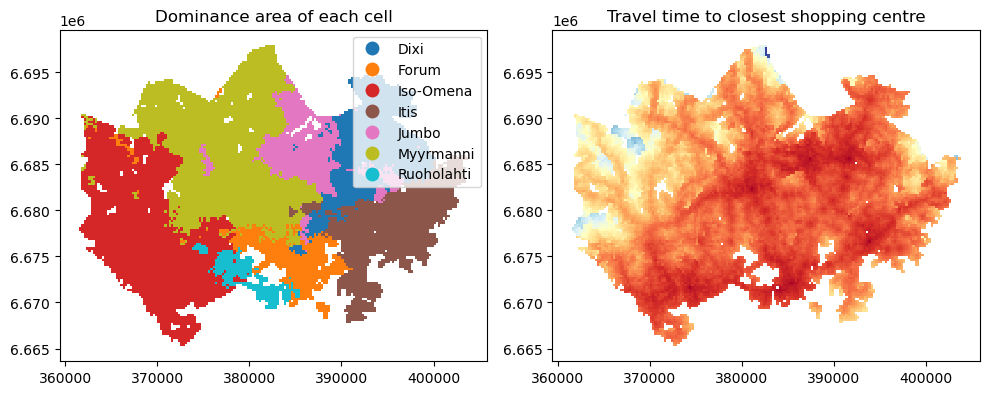

In [107]:
# Changing Omena to Iso-Omena
grid["closest_shopping_centre"] = (grid["closest_shopping_centre"].str.replace("Omena", "Iso-Omena"))

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    nrows=1,
    ncols = 2,
    figsize=(10, 10)
)

# Left: most dominant (closest) shopping centre for each cell
grid.plot(
    column="closest_shopping_centre",
    ax=axes[0],
    legend=True
)
axes[0].set_title("Dominance area of each cell")

# Right: Travel time to the closest shopping centre for each grid cell.
grid.plot(
    column="shortest_traveltime",
    ax=axes[1],
    cmap = "RdYlBu"
)
axes[1].set_title("Travel time to closest shopping centre")


plt.tight_layout()
plt.savefig(
    DATA_DIRECTORY / "dominance_areas.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [108]:
# NON-EDITABLE TEST CELL
# Check that output figure file exists
assert (DATA_DIRECTORY / "dominance_areas.png").exists()


--- 

**Do not forget to plot the result map, and save it to `DATA_DIRECTORY / "dominance_areas.png"`!**

---

## Reflections

This was a significantly more complex exercise that previous ones, and it included finding
a solution yourself. 

- What was most difficult part? 
- Where did you get stuck? 
- What was the easiest, and
- what was the most fun part of this exercise?

Add your answer below

Overall, I really liked that this exercise was more applied and complex than the previous ones, even if I got stuck a few times.
For example, I was stuck with the joining id's at first but managed to handle it. Also, when creating the subplots for problem 1 I was a bit stuck because I was not very familiar with any kind of plotting but it was nice that it was a lot easier then for problem 2. 
I enjoyed writing the code for reading, cleaning and joining the travel datasets first for Itis and Myyrmanni and then getting to automatize it for the other malls with the for-loop. 


---

## Well done!

Congratulations, you completed exercise 4. Good Job!